## Dự đoán điện ở bước kế tiếp — 10 phút
DS66B, nhóm 14: Trần Quang Huy, Bùi Ngọc Thuấn, Nguyễn Hoàng Thành.

52.416 dòng tại Tetouan, từ 01/01 đến 30/12/2017, cách nhau 10 phút, gồm ba khu vực.
Dùng số đo đã biết để dự đoán mức điện sau 10 phút. Một dòng X, ba đáp án y.

Mạch bài: xem dữ liệu → mốc đơn giản → mô hình với 8 số đo → thêm lịch sử → tuần/tháng → tìm tham số → học mức tăng/giảm → thử bỏ biến → tổng hợp.
Mỗi bước có điểm validation và test. Chọn đầu vào, tham số và mô hình bằng train/CV/validation; test chỉ để đối chiếu, không chọn theo test.
Test đã dùng ở các phiên trước, không phải tập kiểm chứng hoàn toàn mới. Các cấu hình và thứ tự thử được xác định trước khi chạy vòng này.


## 1. Công cụ


In [1]:
import numpy as np  # Dùng numpy để tính với các dãy số.
import pandas as pd  # Dùng pandas để đọc và xử lý bảng dữ liệu.
import matplotlib.pyplot as plt  # Dùng matplotlib để vẽ biểu đồ.
from sklearn.base import clone  # Sao chép cấu hình mô hình, học lại từ đầu.
from sklearn.pipeline import make_pipeline  # Ghép các bước xử lý và mô hình thành một chuỗi.
from sklearn.preprocessing import StandardScaler  # Đưa các cột số về thang đo tương đương.
from sklearn.compose import TransformedTargetRegressor  # Chuẩn hóa đáp án và tự đổi dự đoán về đơn vị gốc.
from sklearn.decomposition import PCA  # Dùng PCA để nén các đầu vào tương quan.
from sklearn.neural_network import MLPRegressor  # Dùng mạng nơ-ron cho bài toán dự đoán số.
from sklearn.linear_model import LinearRegression, Ridge, Lasso  # Lấy ba mô hình hồi quy tuyến tính.
from sklearn.neighbors import KNeighborsRegressor  # Lấy mô hình dự đoán từ các mẫu gần nhất.
from sklearn.tree import DecisionTreeRegressor  # Lấy mô hình cây quyết định.
from sklearn.ensemble import RandomForestRegressor  # Lấy mô hình rừng gồm nhiều cây.
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score  # Lấy công cụ chia thời gian, tìm tham số và chấm CV.
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score  # Lấy bốn cách chấm chất lượng dự đoán.
pd.options.display.float_format = '{:,.4f}'.format  # Hiện số với bốn chữ số sau dấu thập phân.


## 2. Xem dữ liệu
Chia ngay sau đọc: 70% đầu train, 15% tiếp validation, 15% cuối test; không xáo trộn.
Hai ô dưới cùng hiện hai dòng đầu train: trước rồi sau đổi tên cột/định dạng giờ. Không sửa giá trị số đo.

### 2.1. Đọc, chia và xem dữ liệu thô


In [2]:
url = 'https://raw.githubusercontent.com/huy1907ddddddd/DS66B_group_14/eaabc962460c76dc76db4a59d3de5a5dfd6329fd/data/raw/Tetuan%20City%20power%20consumption.csv'  # Địa chỉ dữ liệu gốc, cố định phiên bản để chạy lại.
data = pd.read_csv(url)  # Đọc file CSV thành một bảng.
train_end = int(len(data) * 0.70)  # Lấy mốc kết thúc train ở 70% số dòng.
test_start = int(len(data) * 0.85)  # Lấy mốc bắt đầu test sau 85% số dòng.
test = data.iloc[test_start:].copy()  # Tách riêng 15% cuối làm test, chỉ chấm ở cuối.
df = data.iloc[:test_start].copy()  # Giữ 85% đầu để phát triển bằng train và validation.
del data  # Bỏ bảng gốc để tránh vô tình dùng lại toàn bộ dữ liệu.
display(df.iloc[:train_end].head(2))  # Hiện hai dòng train với tên cột và ngày giờ gốc.


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,1/1/2017 0:10,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### 2.2. Đổi tên cột và định dạng giờ
Tên ngắn giúp viết code dễ hơn. Chuyển chuỗi ngày giờ thành thời điểm để tính khoảng cách, lấy giờ/thứ/tháng.


In [3]:
weather = ['temperature', 'humidity', 'wind_speed', 'general_diffuse', 'diffuse']  # Đặt tên năm cột thời tiết và bức xạ.
zones = ['zone_1', 'zone_2', 'zone_3']  # Đặt tên ba cột điện của ba khu vực.
df.columns = ['time'] + weather + zones  # Đổi tên các cột cho ngắn và dễ gọi.
df['time'] = pd.to_datetime(df['time'], format='%m/%d/%Y %H:%M')  # Đổi chuỗi ngày giờ thành kiểu thời gian.
display(df.iloc[:train_end].head(2))  # Hiện hai dòng thật để xem cấu trúc dữ liệu.


,time,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3
0,2017-01-01 00:00:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,2017-01-01 00:10:00,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### Xem mức điện của train theo thời gian

Ba đường tương ứng ba khu vực. Mỗi điểm là mức điện trung bình một ngày, giúp nhìn rõ xu hướng trong gần chín tháng train. Đây là trung bình các số đo, không phải tổng điện năng trong ngày. Chỉ biểu đồ được gom theo ngày; dữ liệu học vẫn cách nhau 10 phút. Không dùng validation hoặc test để vẽ.


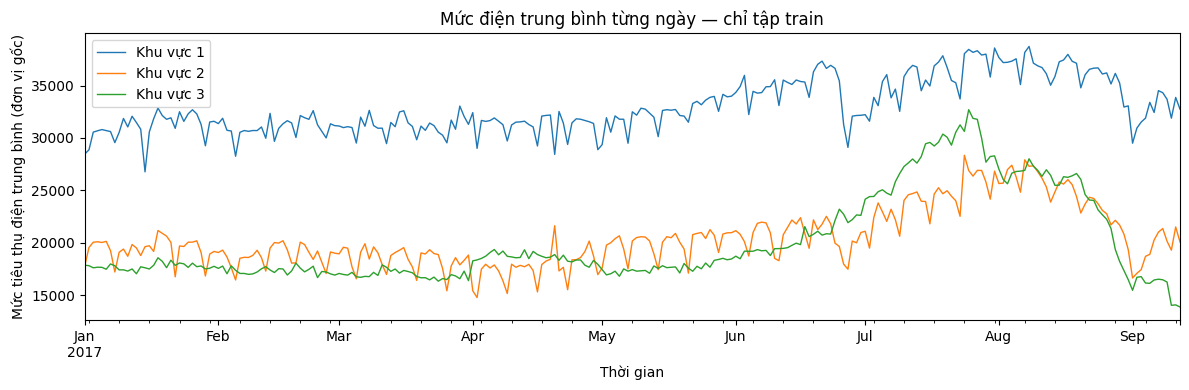

In [4]:
train_view = df.iloc[:train_end]  # Chỉ lấy các dòng train, không lấy validation hay test.
daily_power = train_view.set_index('time')[zones].resample('D').mean()  # Tính mức điện trung bình từng ngày để biểu đồ dễ nhìn.
daily_power.plot(figsize=(12, 4), linewidth=1)  # Vẽ ba đường, mỗi đường ứng với một khu vực.
plt.title('Mức điện trung bình từng ngày — chỉ tập train')  # Ghi rõ nội dung và phạm vi biểu đồ.
plt.xlabel('Thời gian')  # Trục ngang là ngày đo.
plt.ylabel('Mức tiêu thụ điện trung bình (đơn vị gốc)')  # Giữ nguyên đơn vị của dữ liệu.
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])  # Gắn tên cho ba đường.
plt.tight_layout()  # Căn bố cục để không che nhãn.
plt.show()  # Hiện biểu đồ trong notebook.


### EDA — Kiểm tra và xem dữ liệu train
Kiểm tra dữ liệu trước, sau đó mỗi ô code hiện một bảng riêng để dễ đọc. Các bảng thống kê chỉ dùng train.


In [5]:
assert df.notna().all().all() and np.isfinite(df[weather + zones]).all().all()  # Dừng nếu có ô thiếu hoặc số vô hạn trong phần phát triển.
assert not df.time.duplicated().any()  # Dừng nếu có hai dòng trùng thời điểm.
assert df.time.diff().dropna().eq(pd.Timedelta(minutes=10)).all()  # Kiểm tra các dòng liên tiếp cách nhau đúng 10 phút.


### Thống kê chung của train


In [6]:
early = df.iloc[:train_end]  # Chỉ lấy phần train để xem thống kê.
display(early[weather + zones].describe().T)  # Hiện trung bình, nhỏ nhất, lớn nhất và các mốc phân bố.


,count,mean,std,min,25%,50%,75%,max
temperature,"36,691.0000",19.2393,6.1815,3.2470,14.3400,19.1600,24.0400,40.0100
humidity,"36,691.0000",67.6561,16.0826,11.3400,57.3800,69.5200,81.4000,93.6000
wind_speed,"36,691.0000",1.9980,2.3575,0.0500,0.0770,0.0860,4.9130,4.9780
general_diffuse,"36,691.0000",207.6599,285.7269,0.0040,0.0660,18.2100,383.2000,"1,163.0000"
diffuse,"36,691.0000",86.5442,135.8819,0.0190,0.1260,16.4400,119.8000,936.0000
zone_1,"36,691.0000","32,956.8892","7,255.5949","13,895.6962","26,703.4233","33,089.3617","38,195.8804","52,204.3951"
zone_2,"36,691.0000","20,444.8429","5,067.7250","8,560.0815","16,298.7573","20,444.3506","23,875.6239","37,408.8608"
zone_3,"36,691.0000","20,024.4123","6,464.3840","8,189.9081","15,290.1818","18,071.6308","24,821.5674","47,598.3264"


### Mức điện trung bình theo giờ
Ba đường cho ba khu vực, chỉ dùng train. Mỗi điểm là trung bình của khung giờ đó trên tất cả các ngày train; ví dụ điểm 20 giờ gồm các số đo 20:00–20:50. Đây là nhịp trong ngày, không phải diễn biến của một ngày riêng lẻ.


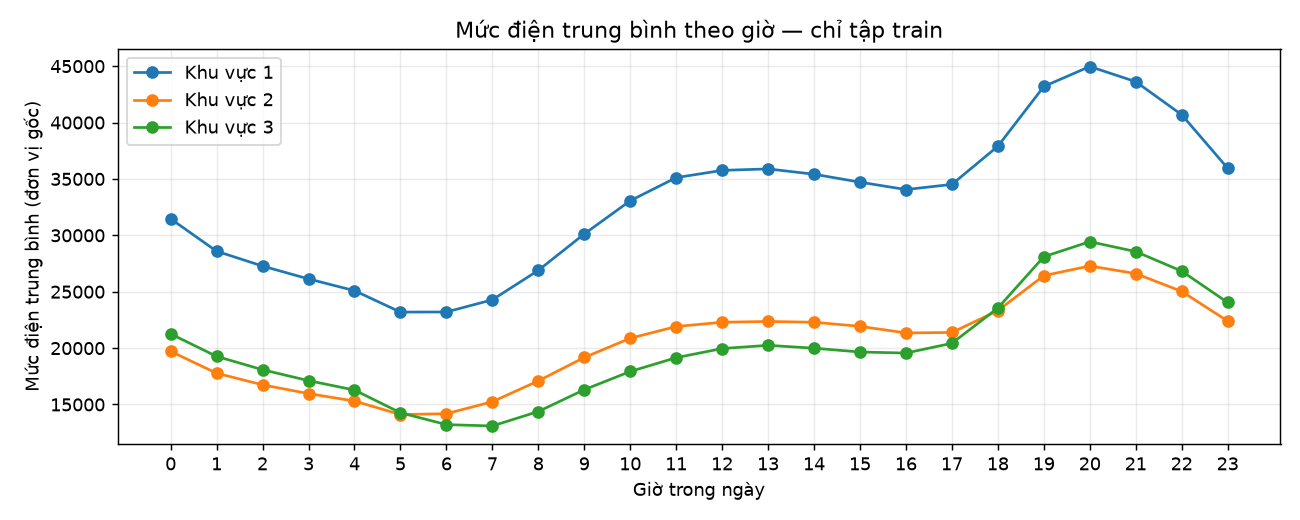

In [ ]:
hourly_power = early.groupby(early.time.dt.hour)[zones].mean()  # Tính mức điện trung bình của từng khung giờ trên train.
hourly_power.plot(marker='o', figsize=(10, 4))  # Vẽ ba đường với 24 điểm cho ba khu vực.
plt.title('Mức điện trung bình theo giờ — chỉ tập train')  # Ghi rõ nội dung và phạm vi dữ liệu.
plt.xlabel('Giờ trong ngày')  # Trục ngang là giờ từ 0 đến 23.
plt.ylabel('Mức điện trung bình (đơn vị gốc)')  # Trục dọc giữ đơn vị gốc của số đo.
plt.xticks(range(24))  # Hiện đủ nhãn 24 giờ.
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])  # Phân biệt ba đường theo khu vực.
plt.grid(alpha=0.25)  # Thêm lưới nhạt để dễ đọc giá trị.
plt.tight_layout()  # Căn hình để nhãn không bị che.
plt.show()  # Hiện biểu đồ ngay dưới ô code.


### Mức điện trung bình theo thứ


In [8]:
display(early.groupby(early.time.dt.dayofweek)[zones].mean().rename_axis('Thứ: 0 = thứ Hai'))  # Xem mức điện trung bình theo thứ trong tuần.


,zone_1,zone_2,zone_3
Thứ: 0 = thứ Hai,,,
0,"33,187.0370","20,737.7564","19,903.2447"
1,"33,209.7260","20,893.8191","19,945.2474"
2,"33,437.3696","20,974.1974","20,063.5439"
3,"33,468.5365","21,176.9508","20,102.8077"
4,"33,067.0187","20,897.2381","19,730.3626"
5,"33,056.3388","19,921.4258","20,324.5895"
6,"31,306.0521","18,547.1306","20,104.0014"


### Mức điện trung bình theo tháng


In [9]:
display(early.groupby(early.time.dt.month)[zones].mean().rename_axis('Tháng'))  # Xem mức điện trung bình theo từng tháng.


,zone_1,zone_2,zone_3
Tháng,,,
1,"31,032.4935","19,394.4447","17,746.0953"
2,"30,985.7536","18,787.7931","17,335.0022"
3,"31,155.1654","18,457.9375","16,947.6860"
4,"31,169.7682","17,633.9664","18,593.1677"
5,"32,396.0092","19,977.2879","17,621.1010"
6,"34,605.5408","20,670.9286","20,430.9415"
7,"35,831.5536","24,147.8869","28,194.1112"
8,"36,435.1896","24,656.2166","24,648.8947"
9,"32,558.6170","19,363.7656","15,781.0580"


## 3. Cách làm ban đầu — chỉ 8 số đo hiện tại
X gồm 5 số đo thời tiết/bức xạ và điện hiện tại của 3 khu vực. y là điện ba khu vực sau 10 phút.
Chưa thêm lag, trung bình hay sin/cos. Giữ cố định các thời điểm đánh giá từ lúc đáp án đủ một tháng lịch sử, vì phần sau sẽ thử lịch sử tháng.
Đây là cách giữ cùng đề kiểm tra cho mọi bước; không chọn thời điểm dựa trên số điện hoặc sai số.


In [10]:
horizon = 1  # Dự đoán một dòng kế tiếp.
time_step = df.time.diff().dropna().mode().iloc[0]  # Lấy khoảng cách thời gian phổ biến: 10 phút.
steps_per_day = int(pd.Timedelta(days=1) / time_step)  # Một ngày có 144 bước.
raw_columns = weather + zones  # Tám đầu vào hiện tại, chưa có lịch sử.
evaluation_start = df.time.iloc[0] + pd.DateOffset(months=1)  # Giữ cùng mốc đủ lịch sử cho các bước sau.
target_time = df.time + horizon * time_step  # Thời điểm cần dự đoán.
y = df[zones].shift(-horizon)  # Đưa số điện dòng sau về làm đáp án dòng hiện tại.
valid = (target_time >= evaluation_start) & y.notna().all(axis=1)  # Chỉ giữ mốc chung có đủ đáp án.
X, y = df.loc[valid, raw_columns], y.loc[valid]  # Lấy đầu vào và đáp án trên cùng các dòng.
origin, target_time = df.time.loc[valid], target_time.loc[valid]  # Giữ giờ dự đoán và giờ có đáp án.
validation_start = df.time.iloc[train_end]  # Mốc bắt đầu validation đã chia lúc đọc.
train = target_time < validation_start  # Đáp án train phải nằm trước validation.
validation = origin >= validation_start  # Validation bắt đầu từ đúng mốc đã chia.
X_train_all, y_train = X.loc[train], y.loc[train]  # Lấy dữ liệu cho mô hình học.
X_val_all, y_val = X.loc[validation], y.loc[validation]  # Lấy dữ liệu chọn phương án.
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)  # Hiện rõ khoảng dự đoán.
print('Train:', len(y_train), '| Validation:', len(y_val))  # Hiện số dòng thực dùng sau khi giữ mốc chung.
assert target_time[train].max() < origin[validation].min()  # Không để đáp án train chạm validation.


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Train: 32227 | Validation: 7861


### Chuẩn bị test để đối chiếu từng bước
Chỉ tạo đầu vào và đáp án để chấm; không fit mô hình, scaler hay PCA bằng test.
Đánh giá cuốn chiếu: lúc dự đoán đã biết số đo hiện tại, chưa biết dòng tiếp theo.


In [11]:
test.columns = df.columns  # Dùng cùng tên cột như phần phát triển.
test['time'] = pd.to_datetime(test['time'], format='%m/%d/%Y %H:%M')  # Đọc ngày giờ test đúng định dạng gốc.
assert test.time.diff().dropna().eq(time_step).all()  # Kiểm tra test vẫn cách nhau 10 phút.
assert test.time.iloc[0] - df.time.iloc[-1] == time_step  # Kiểm tra ranh giới không bị đứt đoạn.
assert test.notna().all().all() and np.isfinite(test[weather + zones]).all().all()  # Dừng nếu test không chấm được do thiếu hoặc vô hạn.
X_test_all = test[raw_columns].iloc[:-horizon].copy()  # Chỉ dùng các số đo đã biết tại mỗi mốc.
y_test = test[zones].shift(-horizon).iloc[:-horizon]  # Dòng kế tiếp là đáp án để chấm.
test_origin = test.time.iloc[:-horizon]  # Giờ bắt đầu dự đoán từng dòng test.
test_target_time = test_origin + horizon * time_step  # Giờ đáp án tương ứng.
assert target_time[validation].max() < test_origin.min()  # Đáp án validation không lấn vào đầu vào test.
print('Số dòng test được chấm:', len(y_test))  # Dòng cuối không có đáp án kế tiếp nên không chấm.


Số dòng test được chấm: 7862


### Cách chấm dùng chung
MAE là độ lệch trung bình, càng nhỏ càng tốt. RMSE nhấn mạnh lỗi lớn; MAPE là phần trăm sai số; R² không phải phần trăm chính xác.
MAE/RMSE/MAPE tính chung ba khu vực, R² trung bình điểm từng khu vực. Hai hàm dưới giúp các bước chấm và hiện bảng theo cùng một cách.


In [12]:
def metrics(truth, predicted):  # Viết hàm chấm điểm dùng chung cho mọi mô hình.
    return [mean_absolute_error(truth, predicted),  # Tính MAE: độ lệch tuyệt đối trung bình.
            np.sqrt(mean_squared_error(truth, predicted)),  # Tính RMSE: chỉ tiêu nhạy hơn với lỗi lớn.
            mean_absolute_percentage_error(truth, predicted) * 100,  # Tính MAPE rồi đổi sang phần trăm.
            r2_score(truth, predicted)]  # Tính R² trung bình của ba khu vực.

metric_names = ['MAE', 'RMSE', 'MAPE (%)', 'R2']  # Đặt tên bốn cột điểm theo đúng thứ tự tính.

result_rows, step_tables = [], []  # Giữ điểm từng cấu hình và từng bước để xuất báo cáo.
val_predictions, train_predictions, test_predictions = {}, {}, {}  # Giữ dự đoán để tính điểm và vẽ.
candidates, candidate_columns = {}, {}  # Giữ mô hình được xét chọn cùng đầu vào tương ứng.
extra_models, extra_columns, delta_names = {}, {}, set()  # Chuẩn bị chỗ cho các thử nghiệm sau.
result_columns = ['Model', 'Số biến'] + ['Validation ' + m for m in metric_names]  # Tên cột validation.
result_columns += ['Train ' + m for m in metric_names] + ['Test ' + m for m in metric_names]  # Thêm tên cột train/test.

def record_result(name, val_pred, train_pred, test_pred, count, eligible=True):  # Chấm một phương án theo cách thống nhất.
    if eligible:  # Chỉ các phương án được chấp nhận mới tham gia chọn cuối.
        val_predictions[name] = val_pred  # Việc chọn cuối chỉ đọc các dự đoán validation này.
    train_predictions[name], test_predictions[name] = train_pred, test_pred  # Giữ dự đoán gốc để đối chiếu sau.
    result_rows.append([name, count, *metrics(y_val, val_pred), *metrics(y_train, train_pred), *metrics(y_test, test_pred)])  # Tính bốn điểm cho từng tập.

def compare_step(step, names, reference):  # Hiện bảng của một bước tối ưu.
    results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')  # Gom các điểm đã tính thành bảng.
    table = results.loc[names].copy()  # Chỉ lấy các phương án thuộc bước đang học.
    table['Giảm Test MAE so với Persistence'] = results.loc['Persistence', 'Test MAE'] - table['Test MAE']  # Số dương là tốt hơn cách đoán giữ nguyên.
    table['Giảm Test MAE so với ' + reference] = results.loc[reference, 'Test MAE'] - table['Test MAE']  # So với mốc trước của bước này.
    display(table.drop(columns=[c for c in table if c.startswith('Train ') or c in ['Validation RMSE', 'Validation MAPE (%)', 'Validation R2']]))  # Hiện bảng gọn, CSV vẫn giữ đủ điểm.
    step_tables.append(table.reset_index().assign(Bước=step))  # Lưu cả tên bước để làm slide/report.


### Mốc đơn giản nhất: điện 10 phút tới bằng điện hiện tại
Ví dụ hiện tại là 30.000 thì đoán 10 phút sau cũng là 30.000. Chưa cần mô hình học.
Mô hình phải vượt được mốc thực tế này thì việc học mới có ích.


In [13]:
record_result('Persistence', X_val_all[zones].to_numpy(), X_train_all[zones].to_numpy(), X_test_all[zones].to_numpy(), 3)  # Đoán bằng đúng ba số điện hiện tại.
compare_step('Mốc giữ nguyên', ['Persistence'], 'Persistence')  # Hiện điểm mốc để so các bước sau.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000


## 4. Mô hình ban đầu — cùng 8 đầu vào
Linear học công thức cộng có trọng số; Ridge/Lasso thêm mức phạt; KNN tìm mẫu gần; cây chia điều kiện; rừng gộp nhiều cây.
PCA + Ridge thử nén đầu vào; MLP là mạng nơ-ron nhỏ. Chưa tìm tham số, chưa thêm lịch sử.
Chuẩn hóa/PCA chỉ học trên train; MLP chuẩn hóa cả đầu vào và đáp án.


In [14]:
models = {  # Lập danh sách mô hình cùng cấu hình ban đầu.
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),  # Chuẩn hóa đầu vào rồi dùng hồi quy tuyến tính.
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=100)),  # Dùng Ridge với mức phạt Alpha ban đầu là 100.
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=200000, tol=0.001, precompute=True)),  # Dùng Lasso với Alpha ban đầu là 10.
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights='distance', n_jobs=2)),  # Dùng 15 mẫu gần nhất, ưu tiên mẫu gần hơn.
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),  # Cây ban đầu sâu tối đa 12, mỗi lá ít nhất 20 mẫu.
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5, random_state=42, n_jobs=2),  # Rừng gồm 60 cây, sâu tối đa 14, mỗi lá ít nhất 5 mẫu.
    'PCA + Ridge': make_pipeline(StandardScaler(), PCA(n_components=0.95), Ridge(alpha=1)),  # Nén để giữ 95% phương sai đầu vào rồi dùng Ridge.
    'MLP': TransformedTargetRegressor(  # Bọc mạng để chuẩn hóa đáp án và tự đổi ngược lúc đoán.
        regressor=make_pipeline(StandardScaler(), MLPRegressor(  # Chuẩn hóa đầu vào trước khi đưa vào mạng.
            hidden_layer_sizes=(32, 16), alpha=0.001, max_iter=500, tol=0.00001,  # Mạng có hai lớp ẩn 32/16 nút, học tối đa 500 vòng.
            n_iter_no_change=30, shuffle=False, early_stopping=False, random_state=42)),  # Chờ 30 vòng ít tiến bộ; giữ thứ tự và seed cố định.
        transformer=StandardScaler())  # Chuẩn hóa từng cột đáp án của mạng.
}  # Hoàn tất danh sách tám mô hình ban đầu.


In [15]:
simple_models = {}  # Giữ riêng các mô hình dùng tám đầu vào.
for name, template in models.items():  # Thử từng loại mô hình với cùng dữ liệu.
    model = clone(template)  # Tạo mô hình mới để không đè bản sẽ dùng ở bước sau.
    model.fit(X_train_all[raw_columns], y_train)  # Chỉ học từ tám số đo hiện tại trong train.
    label = name + ' (8 biến)'  # Ghi rõ đầu vào để không lẫn với bản thêm lịch sử.
    simple_models[label] = model  # Lưu mô hình vừa học.
    candidates[label], candidate_columns[label] = model, raw_columns  # Cho phép xét bản đơn giản ở bước chọn cuối.
    record_result(label, model.predict(X_val_all[raw_columns]), model.predict(X_train_all[raw_columns]), model.predict(X_test_all[raw_columns]), 8)  # Chấm trên cùng các mốc.
compare_step('Mô hình ban đầu', ['Persistence'] + list(simple_models), 'Persistence')  # So tám mô hình với mốc giữ nguyên.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456
Ridge (8 biến),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338
Lasso (8 biến),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166
KNN (8 biến),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154"
Decision Tree (8 biến),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011"
Random Forest (8 biến),8,873.5496,"1,914.0566","2,671.8124",11.1645,0.6796,"-1,620.9436"
PCA + Ridge (8 biến),8,"3,357.4102","4,131.2015","4,708.7962",24.2279,-0.2729,"-3,838.0885"
MLP (8 biến),8,454.2918,754.6490,"1,074.7358",4.1437,0.9377,-461.5360


## 5. Tối ưu 1 — thêm quá khứ và giờ trong ngày
Chỉ biết số hiện tại có thể chưa biết điện đang tăng hay giảm. Thêm các số điện trước đó, trung bình và độ dao động gần đây.
Hàm dưới chuẩn bị cả nhóm tuần/tháng để bước sau dùng; bước này chỉ cho Linear dùng nhóm ngắn hạn 40 biến.

Vì sao có sin/cos? 23 giờ và 0 giờ thực tế chỉ cách một giờ, nhưng hai con số lại chênh 23. Đặt thời gian lên mặt đồng hồ tròn để cuối ngày nối với đầu ngày.
Hai tọa độ sin/cos mô tả vị trí trên vòng tròn; dùng một tọa độ có thể làm hai thời điểm khác nhau trùng nhau. Thứ trong tuần cũng là vòng tròn.
Đây là cách mã hóa chu kỳ thông dụng, không bảo đảm mọi mô hình đều tăng điểm. Chưa có thử nghiệm riêng để quy toàn bộ mức cải thiện cho sin/cos.


In [16]:
def make_features(frame):  # Tạo một hàm dùng chung để làm đầu vào và đáp án.
    future_time = frame.time + horizon * time_step  # Tính thời điểm cần dự đoán từ thời điểm hiện tại.
    X = frame[weather + zones].copy()  # Bắt đầu bằng số đo thời tiết và điện hiện tại.
    for zone in zones:  # Làm giống nhau cho từng khu vực điện.
        for lag in [1, 3, 6, 18, steps_per_day]:  # Chọn các mốc quá khứ: 10, 30, 60, 180 phút và một ngày.
            X[f'{zone}_lag_{lag}'] = frame[zone].shift(lag)  # Lấy số điện đã đo ở mốc quá khứ đó làm đầu vào.
        for window in [6, 18]:  # Xét nhóm 6 dòng và 18 dòng gần nhất.
            X[f'{zone}_mean_{window}'] = frame[zone].rolling(window).mean()  # Tính điện trung bình của nhóm dòng gần nhất.
            X[f'{zone}_std_{window}'] = frame[zone].rolling(window).std()  # Tính mức dao động điện của nhóm dòng gần nhất.
        X[f'{zone}_daily_reference'] = frame[zone].shift(steps_per_day - horizon)  # Lấy điện cùng giờ với đáp án, nhưng ở hôm trước.
        X[f'{zone}_weekly_lag'] = frame[zone].shift(7 * steps_per_day)  # Lấy điện đúng một tuần trước thời điểm hiện tại.
        X[f'{zone}_weekly_reference'] = frame[zone].shift(7 * steps_per_day - horizon)  # Lấy điện cùng giờ với đáp án, nhưng ở tuần trước.
        previous_month = future_time - pd.DateOffset(months=1)  # Lùi giờ cần đoán về cùng ngày, giờ của tháng trước.
        X[f'{zone}_monthly_reference'] = previous_month.map(frame.set_index('time')[zone])  # Tra số điện đã đo tại mốc tháng trước vừa tìm.
    minute = future_time.dt.hour * 60 + future_time.dt.minute  # Đổi giờ cần đoán thành số phút tính từ đầu ngày.
    X['clock_sin'] = np.sin(2 * np.pi * minute / 1440)  # Biểu diễn giờ bằng sin để nối cuối ngày với đầu ngày.
    X['clock_cos'] = np.cos(2 * np.pi * minute / 1440)  # Thêm cos để phân biệt đầy đủ các vị trí trong ngày.
    X['weekday_sin'] = np.sin(2 * np.pi * future_time.dt.dayofweek / 7)  # Biểu diễn thứ trong tuần bằng sin.
    X['weekday_cos'] = np.cos(2 * np.pi * future_time.dt.dayofweek / 7)  # Thêm cos để giữ đúng vòng lặp bảy ngày.
    X['is_weekend'] = (future_time.dt.dayofweek >= 5).astype(float)  # Đánh dấu thứ Bảy, Chủ nhật là 1; ngày khác là 0.
    X['month_sin'] = np.sin(2 * np.pi * (future_time.dt.month - 1) / 12)  # Biểu diễn tháng trong năm bằng sin.
    X['month_cos'] = np.cos(2 * np.pi * (future_time.dt.month - 1) / 12)  # Thêm cos để nối tháng 12 với tháng 1.
    phase = (future_time.dt.day - 1) / future_time.dt.days_in_month  # Tính vị trí của ngày trong tháng, bắt đầu từ 0.
    X['month_day_sin'] = np.sin(2 * np.pi * phase)  # Biểu diễn vị trí trong tháng bằng sin.
    X['month_day_cos'] = np.cos(2 * np.pi * phase)  # Thêm cos để mô tả vòng lặp trong tháng.
    y = frame[zones].shift(-horizon)  # Lấy điện ở dòng kế tiếp làm đáp án để học và chấm.
    valid = X.notna().all(axis=1) & y.notna().all(axis=1)  # Chỉ giữ dòng có đủ đầu vào và đủ đáp án.
    return X.loc[valid], y.loc[valid], frame.time.loc[valid], future_time.loc[valid]  # Trả lại đầu vào, đáp án, lúc dự đoán và lúc đáp án.

X, y, origin, target_time = make_features(df)  # Tạo các bảng từ phần train và validation.
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)  # Hiện khoảng cách dữ liệu và khoảng dự đoán trước.
print('Số đầu vào khi có cả tuần và tháng:', X.shape[1])  # Đếm số đầu vào khi thêm cả tuần và tháng.
display(X.head(2))  # Hiện hai dòng đầu vào đã được tạo.


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Số đầu vào khi có cả tuần và tháng: 56


,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3,zone_1_lag_1,zone_1_lag_3,...,zone_3_monthly_reference,clock_sin,clock_cos,weekday_sin,weekday_cos,is_weekend,month_sin,month_cos,month_day_sin,month_day_cos
4463,11.4700,69.6300,4.9210,0.0480,0.1520,"31,084.5570","19,225.5319","19,477.5904","31,837.9747","33,685.0633",...,"20,240.9639",0.0000,1.0000,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000
4464,11.5700,66.2600,4.9150,0.0590,0.1190,"29,892.2034","18,729.4833","18,848.8040","31,084.5570","32,688.6076",...,"20,131.0843",0.0436,0.9990,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000


In [17]:
old_train_index, old_val_index, old_test_index = X_train_all.index, X_val_all.index, X_test_all.index  # Giữ mốc ban đầu để kiểm tra so sánh công bằng.
validation_start = df.time.iloc[train_end]  # Giữ nguyên ranh giới đã chia.
train, validation = target_time < validation_start, origin >= validation_start  # Loại đáp án vượt ranh giới train.
X_train_all, y_train = X.loc[train], y.loc[train]  # Lấy train có đủ các nhóm đầu vào.
X_val_all, y_val = X.loc[validation], y.loc[validation]  # Lấy validation ở đúng các mốc cũ.
test_history = pd.concat([df.tail(32 * steps_per_day), test])  # Mượn lịch sử đã biết trước test để tạo đầu vào tháng.
X_test_all, y_test, test_origin, test_target_time = make_features(test_history)  # Tạo đầu vào test bằng cùng công thức.
in_test = test_origin >= test.time.iloc[0]  # Không chấm các dòng lịch sử mượn thêm.
X_test_all, y_test = X_test_all.loc[in_test], y_test.loc[in_test]  # Chỉ giữ các dòng dự đoán thuộc test.
test_origin, test_target_time = test_origin.loc[in_test], test_target_time.loc[in_test]  # Giữ giờ test tương ứng.
assert X_train_all.index.equals(old_train_index) and X_val_all.index.equals(old_val_index)  # Train và validation phải đúng các dòng ban đầu.
assert X_test_all.index.equals(old_test_index)  # Test cũng phải đúng các dòng ban đầu.
weekly = [c for c in X if 'weekly_' in c or c.startswith('weekday_') or c == 'is_weekend']  # Nhận diện nhóm tuần.
monthly = [c for c in X if 'monthly_' in c or c.startswith('month_')]  # Nhận diện nhóm tháng.
short = [c for c in X if c not in weekly + monthly]  # Nhóm ngắn hạn chưa có tuần/tháng.
short_model = make_pipeline(StandardScaler(), LinearRegression())  # Giữ cùng Linear để đo tác động của đầu vào.
short_model.fit(X_train_all[short], y_train)  # Học lại với 40 đầu vào ngắn hạn.
candidates['Linear (40 biến)'], candidate_columns['Linear (40 biến)'] = short_model, short  # Lưu mô hình và đúng cột nó đã học.
record_result('Linear (40 biến)', short_model.predict(X_val_all[short]), short_model.predict(X_train_all[short]), short_model.predict(X_test_all[short]), len(short))  # Chấm trên đúng các dòng cũ.
compare_step('Thêm quá khứ và giờ', ['Persistence', 'Linear (8 biến)', 'Linear (40 biến)'], 'Linear (8 biến)')  # So trước/sau, chưa kết luận riêng tác dụng sin/cos.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (8 biến)
Model,,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000,8.4456
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Linear (40 biến),40,166.4142,178.6915,278.4380,0.9275,0.9965,114.4215,122.8672


## 6. Tối ưu 2 — thêm lặp lại theo tuần và tháng
Điện cùng giờ tuần trước có thể gợi ý thói quen lặp lại. Tháng trước có thể giúp hoặc làm nhiễu, nên phải thử.
Giữ cùng Linear và cùng thời điểm, chỉ thay nhóm đầu vào. Chọn nhóm bằng validation trước khi hiện điểm test.
Tháng dùng DateOffset theo lịch; ngày không tồn tại được lùi về ngày cuối tháng trước, không coi mọi tháng đều có 30 ngày.


In [18]:
feature_sets = {'Ngắn hạn': short, '+ Tuần': short + weekly, '+ Tháng': short + monthly, '+ Tuần và tháng': list(X.columns)}  # Bốn phương án cần đối chiếu.
season_rows, season_models = [], {}  # Giữ điểm validation và mô hình từng nhóm.
for name, columns in feature_sets.items():  # Lần lượt thử các nhóm đầu vào.
    model = make_pipeline(StandardScaler(), LinearRegression())  # Dùng cùng loại mô hình cho công bằng.
    model.fit(X_train_all[columns], y_train)  # Chỉ học từ train.
    error = mean_absolute_error(y_val, model.predict(X_val_all[columns]))  # Dùng validation để chọn nhóm.
    season_models[name] = model  # Giữ mô hình để chấm test sau khi chốt nhóm.
    season_rows.append([name, len(columns), error])  # Lưu sai số validation.
seasonality = pd.DataFrame(season_rows, columns=['Nhóm đầu vào', 'Số biến', 'Validation MAE'])  # Tạo bảng lựa chọn, chưa có điểm test.
selected_group = seasonality.loc[seasonality['Validation MAE'].idxmin(), 'Nhóm đầu vào']  # Chốt nhóm chỉ bằng validation.
selected_columns = feature_sets[selected_group]  # Lấy danh sách đầu vào đã chốt.
X_train, X_val = X_train_all[selected_columns], X_val_all[selected_columns]  # Chuẩn bị dữ liệu cho các mô hình bước sau.
X_test = X_test_all[selected_columns]  # Chỉ lấy cùng đầu vào để chấm, không học trên test.
for name, model in season_models.items():  # Sau khi chốt nhóm mới chấm đối chiếu từng nhóm.
    columns = feature_sets[name]  # Mỗi mô hình phải nhận đúng các cột đã học.
    record_result('Linear - ' + name, model.predict(X_val_all[columns]), model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns), eligible=False)  # Nhóm được chọn sẽ được học cùng các mô hình ở ô sau.
display(seasonality)  # Hiện căn cứ chọn nhóm đầu vào.
print('Nhóm được chọn bằng validation:', selected_group)  # Không đổi nhóm theo bảng test bên dưới.
compare_step('Thêm tuần và tháng', ['Linear - ' + name for name in feature_sets], 'Linear (40 biến)')  # So các chu kỳ với mốc ngắn hạn.


,Nhóm đầu vào,Số biến,Validation MAE
0,Ngắn hạn,40,166.4142
1,+ Tuần,49,163.7002
2,+ Tháng,47,168.1104
3,+ Tuần và tháng,56,165.4323


Nhóm được chọn bằng validation: + Tuần


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (40 biến)
Model,,,,,,,,
Linear - Ngắn hạn,40,166.4142,178.6915,278.4380,0.9275,0.9965,114.4215,0.0000
Linear - + Tuần,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,5.1606
Linear - + Tháng,47,168.1104,181.8413,281.0263,0.9499,0.9964,111.2717,-3.1499
Linear - + Tuần và tháng,56,165.4323,176.7311,273.6721,0.9226,0.9966,116.3819,1.9604


### Áp dụng nhóm đầu vào đã chọn cho các mô hình
Tham số vẫn như lúc đầu; lần này chỉ đổi đầu vào. Giữ các bản 8 biến để so lại.
Thêm ba mốc đoán bằng cùng giờ hôm qua, tuần trước, tháng trước. Đây là mốc đối chiếu, không phải mô hình huấn luyện.


In [ ]:
baseline_columns = {  # Lập các cách đoán đơn giản để làm mốc so sánh.
    'Persistence': zones,  # Đoán điện sắp tới bằng đúng số điện hiện tại.
    'Previous day': [f'{z}_daily_reference' for z in zones],  # Đoán bằng số điện cùng giờ ở ngày trước.
    'Previous week': [f'{z}_weekly_reference' for z in zones],  # Đoán bằng số điện cùng giờ ở tuần trước.
    'Previous month': [f'{z}_monthly_reference' for z in zones]  # Đoán bằng số điện cùng giờ ở tháng trước.
}  # Hoàn tất bốn cách đoán đơn giản.


for name, columns in baseline_columns.items():  # Tạo thêm các cách đoán bằng lịch sử.
    if name != 'Persistence':  # Persistence đã chấm ở mốc ban đầu.
        record_result(name, X_val_all[columns].to_numpy(), X_train_all[columns].to_numpy(), X_test_all[columns].to_numpy(), len(columns))  # Không cần fit các cách đoán trực tiếp.
for name, model in models.items():  # Giữ cấu hình ban đầu, đổi sang nhóm đầu vào đã chọn.
    model.fit(X_train, y_train)  # Chỉ học trên train.
    candidates[name], candidate_columns[name] = model, selected_columns  # Giữ riêng với bản tám biến.
    record_result(name, model.predict(X_val), model.predict(X_train), model.predict(X_test), len(selected_columns))  # Chấm bằng cùng hàm và cùng mốc.
initial_results = pd.DataFrame([[name, *metrics(y_val, val_predictions[name])] for name in models], columns=['Model'] + metric_names).set_index('Model')  # Giữ bảng validation cho mô hình trước tìm tham số.
compare_step('Áp dụng đầu vào cho các mô hình', list(simple_models) + list(models), 'Linear (8 biến)')  # Hiện cả trước và sau thay đổi đầu vào.


## 7. Tối ưu 3 — tìm tham số
Giữ đầu vào, thử cấu hình bằng ba lượt CV theo thời gian trong train, chừa một dòng ở ranh giới.
Chọn tham số theo CV MAE; sau mỗi nhóm hiện điểm trước/sau trên validation và test. Không chỉnh tham số dựa vào test.
Danh sách cấu hình hữu hạn, không gọi là tối ưu tuyệt đối. Bản tìm tham số có thể kém hơn bản đầu trên validation/test.


In [ ]:
cv = TimeSeriesSplit(n_splits=3, gap=horizon)  # Chia ba lượt theo thời gian, không học từ tương lai.
tuned, searches, tuning_rows = {}, {}, []  # Lưu mô hình, chi tiết tìm kiếm và bảng kết quả.

def tune_model(name, grid):  # Tìm tham số cho một mô hình.
    search = GridSearchCV(models[name], grid, scoring='neg_mean_absolute_error', cv=cv, n_jobs=1, error_score='raise')  # Thử cấu hình bằng CV MAE.
    search.fit(X_train, y_train)  # Toàn bộ tìm kiếm và chuẩn hóa chỉ học từ train.
    model = search.best_estimator_  # Lấy cấu hình tốt nhất theo CV.
    tuned[name], searches[name] = model, search  # Giữ mô hình và các điểm CV.
    label = name + ' (tuned)'  # Phân biệt với bản chưa tìm tham số.
    candidates[label], candidate_columns[label] = model, selected_columns  # Lưu đúng mô hình và đầu vào.
    val_pred = model.predict(X_val)  # Dự đoán validation để chọn cuối.
    record_result(label, val_pred, model.predict(X_train), model.predict(X_test), len(selected_columns))  # Chấm test để đối chiếu, không dùng chọn tham số.
    tuning_rows.append([name, search.best_params_, -search.best_score_, mean_absolute_error(y_val, val_pred)])  # Lưu tham số và sai số CV/validation.
    print(name, '| Tham số:', search.best_params_, '| CV MAE:', -search.best_score_)  # Hiện cấu hình đã chọn.
    compare_step('Tìm tham số - ' + name, [name, label], name)  # Hiện bảng trước/sau của đúng mô hình đó.


### Ridge và Lasso
Tên ridge__alpha nghĩa là chỉnh Alpha của bước Ridge bên trong pipeline. Lasso dùng tương tự.


In [ ]:
tune_model('Ridge', {'ridge__alpha': [0.001, 0.1, 1, 10, 100, 1000]})  # Thử sáu giá trị Alpha cho Ridge trong pipeline.
tune_model('Lasso', {'lasso__alpha': [0.1, 1, 10, 100]})  # Thử bốn giá trị Alpha cho Lasso trong pipeline.


### KNN và đồ thị K
Chọn K bằng MAE nhỏ nhất trên CV. Đường cong để nhìn xu hướng, không đoán K bằng mắt.


In [ ]:
tune_model('KNN', {'kneighborsregressor__n_neighbors': [3, 5, 9, 15, 21, 31]})  # Thử sáu giá trị K và chọn bằng MAE CV.
search = searches['KNN']  # Lấy lại kết quả tìm K vừa chạy.
k_scores = pd.DataFrame({'K': search.cv_results_['param_kneighborsregressor__n_neighbors'],  # Lấy danh sách K đã thử để lập bảng.
                         'CV MAE': -search.cv_results_['mean_test_score']})  # Đổi điểm CV dấu âm thành MAE dương dễ đọc.
display(k_scores)  # Hiện K và độ sai tương ứng.
k_scores.plot(x='K', y='CV MAE', marker='o', figsize=(7, 3))  # Vẽ đường cong MAE theo K.
plt.tight_layout()  # Chỉnh khoảng trống để nhãn không bị cắt.
plt.show()  # Hiện biểu đồ để nhìn xu hướng khi K thay đổi.


### Cây và rừng
Chạy tìm tham số cho cả hai. Rừng giữ 60 cây để thời gian chạy vừa phải.


In [ ]:
tune_model('Decision Tree', {'max_depth': [6, 12, 18, None], 'min_samples_leaf': [5, 20]})  # Thử độ sâu và số mẫu tối thiểu ở lá của cây.
tune_model('Random Forest', {'max_depth': [10, 18, None], 'min_samples_leaf': [2, 10]})  # Thử độ sâu và số mẫu tối thiểu ở lá của rừng.


### PCA và MLP
PCA và bộ chuẩn hóa được học lại trong mỗi lượt CV.
Với MLP, regressor__mlpregressor đi vào mạng bên trong bộ chuẩn hóa đáp án; hidden_layer_sizes là số nút ở từng lớp ẩn.
MLP không dùng early stopping với phép chia ngẫu nhiên. Shuffle=False giữ thứ tự các mẫu khi học.


In [ ]:
tune_model('PCA + Ridge', {'pca__n_components': [0.90, 0.95, 0.99, 0.999], 'ridge__alpha': [0.1, 10]})  # Thử mức giữ phương sai PCA và Alpha của Ridge.
tune_model('MLP', {'regressor__mlpregressor__hidden_layer_sizes': [(32,), (32, 16)],  # Thử mạng MLP có một hoặc hai lớp ẩn.
                   'regressor__mlpregressor__alpha': [0.001, 0.1]})  # Thử hai mức phạt Alpha cho mạng.
tuning_results = pd.DataFrame(tuning_rows, columns=['Model', 'Tham số chọn', 'CV MAE', 'Validation MAE'])  # Gom tham số chọn và điểm của bảy mô hình đã tối ưu.
display(tuning_results)  # Hiện bảng trước khi thử các hướng tối ưu thêm.


## 8. Tối ưu 4 — học mức tăng/giảm
Thay vì hỏi điện sắp tới là bao nhiêu, hỏi điện sẽ tăng/giảm bao nhiêu so với hiện tại. Dự đoán xong cộng lại mức hiện tại.
Thử với RF/MLP đã tìm tham số; giữ nguyên tham số để chỉ đo tác động đổi đáp án. Chưa tìm tham số riêng cho delta.
Clone học lại cả bộ chuẩn hóa đáp án, không dùng thang đo cũ. Không cắt mức giảm âm.


In [ ]:
delta_train = y_train.to_numpy() - X_train_all[zones].to_numpy()  # Lấy điện tương lai trừ điện hiện tại đúng từng hàng, được mức tăng hoặc giảm.
delta_names, delta_rows = set(), []  # Chuẩn bị danh sách tên mô hình delta và bảng điểm của chúng.
for name in ['Random Forest', 'MLP']:  # Thử cách học mức tăng giảm cho Random Forest rồi MLP.
    model = clone(tuned[name])  # Tạo bản chưa học từ cấu hình đã chọn, để học loại đáp án mới.
    cv_errors = -cross_val_score(model, X_train, delta_train, scoring='neg_mean_absolute_error',  # Chấm sai số phần thay đổi; cộng cùng mức hiện tại không làm đổi MAE.
                                 cv=cv, n_jobs=1, error_score='raise')  # Dùng các lượt thời gian trong train, chạy lần lượt; có lỗi thì dừng.
    model.fit(X_train, delta_train)  # Học mức tăng giảm; MLP cũng học lại bộ chuẩn hóa đáp án trên chính delta.
    label = name + ' (delta)'  # Thêm chữ delta để phân biệt với mô hình dự đoán trực tiếp số điện.
    predicted = X_val_all[zones].to_numpy() + model.predict(X_val)  # Cộng mức thay đổi dự đoán vào điện hiện tại đúng từng hàng của validation.
    extra_models[label], extra_columns[label] = model, selected_columns  # Giữ mô hình delta và danh sách đầu vào nó đã học.
    delta_names.add(label)  # Đánh dấu tên này cần cộng lại điện hiện tại khi dự đoán.
    val_predictions[label] = predicted  # Đưa dự đoán số điện đã cộng lại vào bảng chung.
    before_mae = mean_absolute_error(y_val, val_predictions[name + ' (tuned)'])  # Lấy MAE của mô hình đã tối ưu trước đó để đối chiếu cùng validation.
    candidates[label], candidate_columns[label] = model, selected_columns  # Lưu mô hình dự đoán phần thay đổi.
    record_result(label, predicted, X_train_all[zones].to_numpy() + model.predict(X_train), X_test_all[zones].to_numpy() + model.predict(X_test), len(selected_columns))  # Cộng mức hiện tại rồi chấm đúng đơn vị gốc.
    compare_step('Học mức tăng/giảm - ' + name, [name + ' (tuned)', label], name + ' (tuned)')  # So cùng mô hình trước và sau đổi đáp án.
    delta_rows.append([label, before_mae, cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])  # Ghi điểm trước và sau khi đổi đáp án, cùng điểm CV của delta.
delta_results = pd.DataFrame(delta_rows, columns=['Model', 'Validation MAE trước', 'CV MAE delta', 'CV độ lệch chuẩn'] + metric_names).set_index('Model')  # Lập bảng so sánh hai cách học đáp án cho từng mô hình.
display(delta_results)  # Hiện bảng để xem học mức tăng giảm có giúp dự đoán tốt hơn không.


## 9. Tối ưu 5 — thử bỏ nhóm đầu vào
Nhiều đầu vào chưa chắc tốt. Giữ cùng Linear, cùng CV, cùng thời điểm; thử bỏ từng nhóm và một tập gọn.
Chỉ nhận phương án giảm biến nếu cả CV MAE và validation MAE đều thấp hơn bản giữ nguyên. Đây là quy tắc thực dụng, không phải kiểm định thống kê.
Hiện cả điểm test của các phương án để đối chiếu; không đổi quy tắc dựa trên test.


In [ ]:
removals = {  # Liệt kê sáu nhóm đầu vào sẽ thử bỏ riêng từng nhóm.
    'Bỏ thời tiết': weather,  # Thử bỏ năm cột thời tiết.
    'Bỏ độ lệch chuẩn': [c for c in selected_columns if '_std_' in c],  # Thử bỏ các cột đo mức dao động gần đây.
    'Bỏ trung bình': [c for c in selected_columns if '_mean_' in c],  # Thử bỏ các cột trung bình điện gần đây.
    'Bỏ cả nhóm rolling': [c for c in selected_columns if '_std_' in c or '_mean_' in c],  # Thử bỏ cả trung bình và độ dao động gần đây.
    'Bỏ lag 3/6/18': [f'{z}_lag_{lag}' for z in zones for lag in [3, 6, 18]],  # Thử bỏ điện trước 30 phút, 1 giờ và 3 giờ của ba khu vực.
    'Bỏ lịch sử tuần': [c for c in selected_columns if '_weekly_' in c]  # Thử bỏ số điện tham chiếu theo tuần, vẫn giữ thứ và cuối tuần.
}  # Chốt danh sách những nhóm cần thử bỏ.
ablation_columns = {'Giữ nguyên': selected_columns}  # Giữ một phương án đủ đầu vào để làm mốc so sánh.
for name, removed in removals.items():  # Lần lượt xét từng nhóm định bỏ.
    ablation_columns[name] = [c for c in selected_columns if c not in removed]  # Tạo bộ cột còn lại sau khi bỏ nhóm đang xét.
compact = zones + [f'{z}_lag_{lag}' for z in zones for lag in [1, 3]]  # Bắt đầu tập gọn bằng điện hiện tại, trước 10 phút và trước 30 phút.
compact += [c for c in selected_columns if '_mean_' in c]  # Giữ thêm trung bình điện gần đây trong tập gọn.
compact += ['clock_sin', 'clock_cos', 'weekday_sin', 'weekday_cos', 'is_weekend']  # Giữ giờ, thứ và thông tin cuối tuần.
compact += [f'{z}_daily_reference' for z in zones] + [f'{z}_weekly_reference' for z in zones]  # Giữ điện đúng khung giờ cần đoán của hôm trước và tuần trước.
ablation_columns['Tập gọn'] = compact  # Thêm tập gọn vào danh sách phương án cần thử.
feature_models, feature_predictions, feature_rows = {}, {}, []  # Chuẩn bị chỗ giữ mô hình, dự đoán và bảng điểm của từng phương án.
for name, columns in ablation_columns.items():  # Lần lượt thử mọi phương án đầu vào đã liệt kê.
    model = make_pipeline(StandardScaler(), LinearRegression())  # Ghép chuẩn hóa đầu vào với Linear để các phương án được học giống nhau.
    cv_errors = -cross_val_score(model, X_train_all[columns], y_train,  # Chấm ba lượt trong train; đổi điểm âm của thư viện thành MAE dương.
                                 scoring='neg_mean_absolute_error', cv=cv, error_score='raise')  # Chia theo thời gian, chấm bằng MAE; có lỗi thì dừng.
    model.fit(X_train_all[columns], y_train)  # Học lại Linear bằng toàn bộ train với đúng bộ cột đang thử.
    predicted = model.predict(X_val_all[columns])  # Dùng bộ cột đó để dự đoán validation.
    feature_models[name], feature_predictions[name] = model, predicted  # Giữ lại mô hình đã học và các số vừa dự đoán.
    record_result('Bỏ biến - ' + name, predicted, model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns), eligible=False)  # Chấm mọi phương án; chỉ nhận vào chọn cuối nếu đạt quy tắc CV/validation.
    feature_rows.append([name, len(columns), cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])  # Ghi số biến, MAE các lượt CV và bốn điểm đánh giá trên validation.
feature_ablation = pd.DataFrame(feature_rows, columns=['Phương án', 'Số biến', 'CV MAE', 'CV độ lệch chuẩn'] + metric_names).set_index('Phương án')  # Gom điểm thành bảng, lấy tên phương án làm nhãn mỗi hàng.
display(feature_ablation)  # Hiện bảng để đối chiếu đủ biến và các cách giảm biến.
reference = feature_ablation.loc['Giữ nguyên']  # Lấy điểm của phương án giữ nguyên làm mốc.
approved_features = feature_ablation[(feature_ablation['CV MAE'] < reference['CV MAE']) & (feature_ablation.MAE < reference.MAE)]  # Chỉ chấp nhận giảm biến nếu cả CV MAE và validation MAE đều thấp hơn mốc.
# Giữ các mô hình delta từ bước trước, không xóa khi thử bỏ biến.  # Chuẩn bị chỗ chứa các mô hình bổ sung và bộ cột tương ứng.
for name in approved_features.index:  # Chỉ xét những phương án đã đạt cả hai điều kiện.
    label = 'Linear - ' + name  # Đặt tên riêng để nhận ra Linear dùng bộ biến rút gọn.
    extra_models[label], extra_columns[label] = feature_models[name], ablation_columns[name]  # Giữ đúng mô hình và bộ cột đã tạo ra kết quả này.
    val_predictions[label] = feature_predictions[name]  # Cho phương án đạt quy tắc vào chọn cuối.
    candidates[label], candidate_columns[label] = feature_models[name], ablation_columns[name]  # Giữ đúng đầu vào của mô hình được nhận.  # Thêm dự đoán của phương án đạt yêu cầu vào bảng so sánh chung.
print('Cách giảm biến đạt cả hai tiêu chí:', approved_features.index.tolist())  # Thông báo các cách giảm biến đã vượt cả hai tiêu chí.

compare_step('Thử bỏ nhóm đầu vào', ['Bỏ biến - ' + name for name in ablation_columns], 'Linear')  # So với Linear giữ đủ nhóm đã chọn.


## 10. Chốt và tổng hợp
Chọn bằng MAE validation trong các phương án đủ điều kiện. Không chọn mô hình bằng điểm test.
Giữ các bản đơn giản, bản thêm đầu vào, bản tìm tham số và delta để đối chiếu. Các phương án bỏ biến không đạt quy tắc chỉ xuất hiện trong bảng thử nghiệm.


In [ ]:
validation_rows = [[name, *metrics(y_val, predicted)] for name, predicted in val_predictions.items()]  # Chỉ chấm các phương án đủ điều kiện chọn.
validation_results = pd.DataFrame(validation_rows, columns=['Model'] + metric_names).set_index('Model').sort_values('MAE')  # Xếp bằng validation, không đọc điểm test.
best_name = validation_results.index[0]  # Chốt phương án có MAE validation nhỏ nhất.
all_results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')  # Gom kết quả mọi thử nghiệm đã chạy.
train_test_results = all_results.loc[validation_results.index, [c for c in all_results if c.startswith('Train ') or c.startswith('Test ')]]  # Bảng train/test của các ứng viên đủ điều kiện.
best_test_prediction = test_predictions[best_name]  # Lấy dự đoán test có sẵn của phương án đã chọn bằng validation.
display(validation_results)  # Hiện căn cứ chốt mô hình.
display(train_test_results)  # Giữ đủ MAE, RMSE, MAPE và R² của train/test.
print('Chọn bằng validation:', best_name, '| Số dòng test:', len(y_test))  # Nêu rõ tập dùng để chọn.
display(train_test_results.loc[[best_name]])  # Hiện riêng điểm của phương án chốt.
progress_table = pd.concat(step_tables, ignore_index=True)  # Nối bảng từng bước để dùng làm slide/report.
zone_mae = pd.DataFrame({zone: {name: mean_absolute_error(y_test[zone], predicted[:, i]) for name, predicted in test_predictions.items()} for i, zone in enumerate(zones)})  # Chấm riêng từng khu vực để không che lỗi bằng một điểm chung.
display(zone_mae.loc[[best_name, 'Persistence']])  # Đối chiếu mô hình chốt và mốc đơn giản theo khu vực.


### Một dự đoán thật
Lấy thời điểm đầu validation: mức hiện tại, số thật sau 10 phút, dự đoán và sai số từng khu vực.
MAE của một thời điểm khác MAE cả tập.


In [ ]:
example = pd.DataFrame({'Hiện tại': X_val_all[zones].iloc[0],  # Bắt đầu bảng ví dụ bằng điện hiện tại của ba khu vực ở dòng validation đầu tiên.
                        'Thực tế sau 10 phút': y_val.iloc[0],  # Đặt cạnh đó điện thực tế sau 10 phút của cùng dòng.
                        'Dự đoán': val_predictions[best_name][0]})  # Thêm ba dự đoán của phương án đã chọn, kể cả khi đó là cách đoán đơn giản.
example['Sai số tuyệt đối'] = (example['Thực tế sau 10 phút'] - example['Dự đoán']).abs()  # Lấy chênh lệch dự đoán với thực tế và bỏ dấu âm để xem độ lệch từng khu vực.
print('Lúc dự đoán:', origin[validation].iloc[0], '| Lúc đáp án:', target_time[validation].iloc[0])  # In giờ bắt đầu dự đoán và giờ của đáp án để kiểm tra đúng 10 phút.
display(example)  # Hiện ba khu vực cạnh nhau để đối chiếu số thật và số dự đoán.
print('MAE của riêng thời điểm này:', example['Sai số tuyệt đối'].mean())  # Lấy trung bình sai số ba khu vực ở riêng thời điểm này, không phải toàn validation.


## 11. Sai số theo thời gian
Bảng tuần/tháng so Persistence và ba phương án tốt nhất theo validation. Mỗi ô là MAE chung ba khu vực, gắn với giờ có đáp án. Tuần đầu/cuối có thể chưa đủ bảy ngày.


In [ ]:
row_errors = {name: np.abs(y_test.to_numpy() - predicted).mean(axis=1)  # Tại mỗi thời điểm test, lấy trung bình sai số tuyệt đối của ba khu vực.
              for name, predicted in test_predictions.items()}  # Làm việc đó cho từng phương án dự đoán, giữ đúng thứ tự các hàng test.
errors_by_time = pd.DataFrame(row_errors, index=pd.DatetimeIndex(test_target_time, name='Thời điểm đáp án'))  # Ghép các sai số theo đúng giờ đáp án để có thể xem theo tuần hoặc tháng.
weekly_mae = errors_by_time.groupby(errors_by_time.index.to_period('W')).mean()  # Gom những thời điểm cùng tuần rồi lấy MAE trung bình của tuần đó.
monthly_mae = errors_by_time.groupby(errors_by_time.index.to_period('M')).mean()  # Gom những thời điểm cùng tháng rồi lấy MAE trung bình của tháng đó.
show_models = list(dict.fromkeys(['Persistence'] + validation_results.index[:3].tolist()))  # Chọn Persistence và ba phương án đứng đầu validation; bỏ tên trùng mà giữ thứ tự.
print('MAE theo tuần:')  # Gắn nhãn cho phần bảng sai số theo tuần.
display(weekly_mae[show_models])  # Hiện MAE từng tuần của các phương án vừa chọn.
print('MAE theo tháng:')  # Gắn nhãn cho phần bảng sai số theo tháng.
display(monthly_mae[show_models])  # Hiện MAE từng tháng để xem giai đoạn nào dự đoán khó hơn.
plot_zone = 'zone_1'  # Chọn khu vực 1 để xem chi tiết trên biểu đồ tiếp theo.
zone_index = zones.index(plot_zone)  # Tìm vị trí cột của khu vực 1 trong mảng dự đoán ba khu vực.
timeline = pd.DataFrame({'Lúc dự đoán': test_origin.to_numpy(), 'Lúc đáp án': test_target_time.to_numpy(),  # Bắt đầu bảng theo thời gian bằng giờ dự đoán và giờ của đáp án.
                         'Thực tế': y_test[plot_zone].to_numpy(), 'Dự đoán': best_test_prediction[:, zone_index]})  # Thêm số thật và số dự đoán của đúng khu vực đã chọn.
timeline['Sai số tuyệt đối'] = (timeline['Thực tế'] - timeline['Dự đoán']).abs()  # Tính độ lệch tuyệt đối từng thời điểm cho riêng khu vực này.
display(timeline.head(12))  # Hiện 12 hàng đầu để kiểm tra các giờ, số thật và số dự đoán khớp nhau.


## 12. Biểu đồ hai đường: thực tế và dự đoán
Hiện 7 ngày đầu test để nhìn rõ từng lần tăng/giảm. Bảng điểm vẫn tính trên toàn bộ test.
Đổi plot_zone ở phần 11 nếu muốn xem khu vực khác. Hai đường dùng cùng thời điểm đáp án.


In [ ]:
shown = timeline[timeline['Lúc đáp án'] < timeline['Lúc đáp án'].iloc[0] + pd.Timedelta(days=7)]  # Chỉ lấy bảy ngày đầu trong bảng test để hai đường dễ nhìn.
fig, ax = plt.subplots(figsize=(13, 4))  # Tạo khung hình rộng để vẽ theo thời gian.
ax.plot(shown['Lúc đáp án'], shown['Thực tế'], label='Thực tế', linewidth=1.4)  # Vẽ số điện thực tế theo giờ đáp án.
ax.plot(shown['Lúc đáp án'], shown['Dự đoán'], label='Dự đoán', linewidth=1.1, alpha=0.85)  # Vẽ số dự đoán trên cùng giờ để nhìn chỗ trùng và chỗ lệch.
ax.set(title=f'{plot_zone} — dự đoán bước kế tiếp — {best_name}', xlabel='Thời điểm đáp án', ylabel='Số điện (đơn vị gốc)')  # Ghi rõ khu vực, mô hình, thời điểm đáp án và đơn vị gốc của số điện.
ax.legend()  # Hiện chú giải để phân biệt đường thực tế và dự đoán.
fig.autofmt_xdate()  # Xoay và sắp xếp nhãn ngày giờ cho dễ đọc.
fig.tight_layout()  # Chỉnh khoảng cách trong hình để chữ không bị cắt.
fig.savefig('next_step_forecast.png', dpi=160)  # Lưu biểu đồ thành ảnh PNG để dùng lại trong báo cáo.
plt.show()  # Hiện biểu đồ ngay dưới ô code.


## 13. Lưu kết quả
Các bảng CSV và ảnh được tạo lại khi chạy. Bảng optimization_progression.csv giữ kết quả từng bước; bảng all_experiment_results.csv giữ mọi cấu hình đã thử.
Kết luận dựa vào bảng chạy thật, kể cả bước không cải thiện. Thêm mô hình, tham số hoặc tháng không bảo đảm tốt hơn.


In [ ]:
feature_ablation.to_csv('feature_ablation_comparison.csv')  # Lưu bảng thử giảm biến để đối chiếu số cột và điểm đánh giá.
delta_results.to_csv('delta_target_comparison.csv')  # Lưu bảng so sánh học số điện trực tiếp với học mức tăng giảm.
seasonality.to_csv('seasonality_comparison.csv', index=False)  # Lưu bảng thử thông tin theo tuần và tháng, bỏ cột số thứ tự.
validation_results.to_csv('validation_model_comparison.csv')  # Lưu bảng validation đã dùng để chọn phương án.
tuning_results.to_csv('tuning_comparison.csv', index=False)  # Lưu kết quả tìm tham số của các mô hình.
train_test_results.to_csv('train_test_model_comparison.csv')  # Lưu bảng điểm train và test để kiểm tra độ lệch giữa hai giai đoạn.
weekly_mae.to_csv('mae_by_week.csv')  # Lưu bảng MAE theo tuần.
monthly_mae.to_csv('mae_by_month.csv')  # Lưu bảng MAE theo tháng.
forecast_table = pd.DataFrame({'origin': test_origin.to_numpy(), 'target_time': test_target_time.to_numpy()})  # Tạo bảng chi tiết, mỗi hàng giữ đúng giờ dự đoán và giờ đáp án của test.
for i, zone in enumerate(zones):  # Lần lượt thêm kết quả của ba khu vực theo đúng vị trí cột.
    forecast_table[zone + '_actual'] = y_test[zone].to_numpy()  # Ghi số điện thực tế của khu vực đang xét.
    forecast_table[zone + '_predicted'] = best_test_prediction[:, i]  # Ghi dự đoán của phương án đã chốt cho đúng khu vực đó.
    forecast_table[zone + '_absolute_error'] = np.abs(y_test[zone].to_numpy() - best_test_prediction[:, i])  # Ghi sai số tuyệt đối của từng dự đoán để tra lại được từng hàng.
forecast_table.to_csv('next_step_predictions.csv', index=False)  # Lưu toàn bộ dự đoán test và đáp án của ba khu vực thành CSV.
print('Chu kỳ được chọn:', selected_group, '| Mô hình được chọn trên validation:', best_name)  # Nhắc lại nhóm đầu vào và mô hình đã chọn bằng validation.
print('MAE validation:', validation_results.loc[best_name, 'MAE'])  # In MAE validation của phương án đã chốt.
print('MAE test:', train_test_results.loc[best_name, 'Test MAE'])  # In MAE test của chính phương án đó, không đổi sang mô hình khác.
all_results.to_csv('all_experiment_results.csv')  # Lưu cả các phương án thử rồi loại.
progress_table.to_csv('optimization_progression.csv', index=False)  # Lưu bảng trước/sau của từng bước.
zone_mae.to_csv('test_mae_by_zone.csv')  # Lưu sai số riêng cho ba khu vực.
print('Đã lưu 12 bảng CSV và ảnh next_step_forecast.png.')  # Báo tên các kết quả đã xuất.  # Thông báo đã tạo đủ chín bảng CSV và ảnh biểu đồ.


### Phạm vi, việc chưa thử và nguồn
Dữ liệu chỉ có Tetouan năm 2017. Kết quả không tự động áp dụng cho doanh nghiệp hoặc năm khác.
Test đã được chấm ở các phiên trước và tiếp tục được đối chiếu sau từng bước theo yêu cầu nhóm. Không gọi đây là kiểm chứng trên tập hoàn toàn mới; muốn kiểm chứng độc lập cần dữ liệu tương lai mới.
Các thử nghiệm chọn bằng train/CV/validation. Bảng test có thể giúp mô tả kết quả, không được dùng để chọn các lượt thử tiếp theo.
Chưa thử cây riêng từng khu vực. Linear hiện tại đã có bộ hệ số riêng cho ba đáp án; tách ba lệnh fit với cùng X không phải một cải tiến mới.
Chưa tách thử nghiệm riêng bỏ/giữ sin/cos, nên không quy phần cải thiện chung cho riêng cách mã hóa này.
MLP theo chương 11, metrics chương 13, PCA chương 14. Không ép phân cụm vào bài hồi quy.
Cần đối chiếu yêu cầu chia dữ liệu/ngôn ngữ/template môn học trước khi nộp. Bản này dùng tiếng Việt để nhóm học hiểu.

Nguồn: [UCI Tetouan](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city), [yêu cầu môn học](https://docs.google.com/spreadsheets/d/17AhxqqU-uAUvH9RTIqbgO1w13_obfjTln45ukoH7SmM/edit), [GitHub nhóm](https://github.com/huy1907ddddddd/DS66B_group_14).
